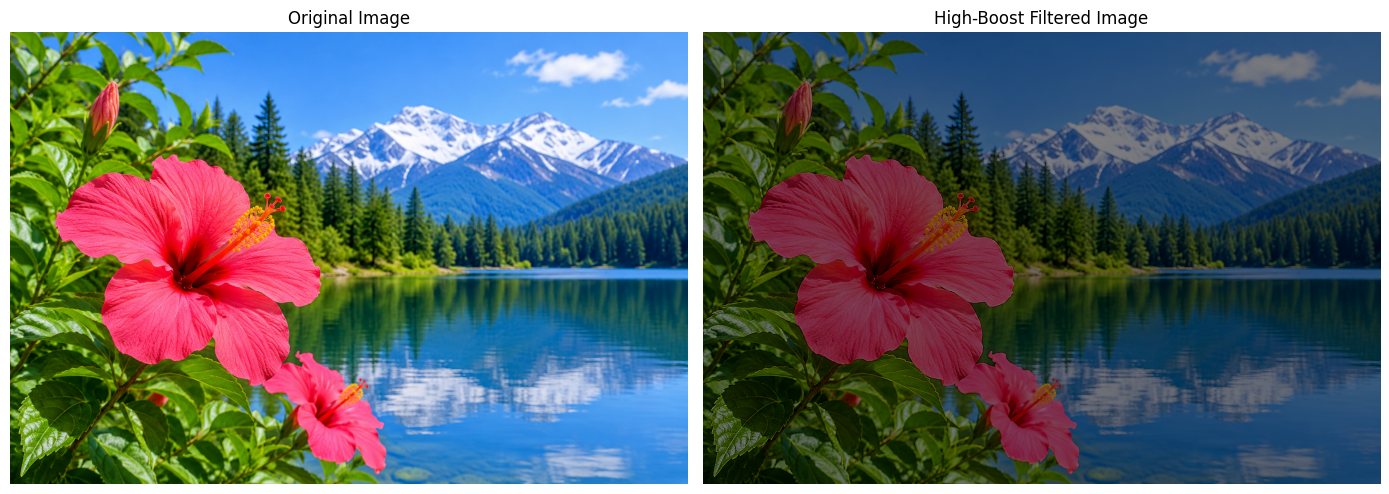

High-Boost Filtering Completed Successfully!


In [1]:
#  High-Boost Filtering
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread("image.jpg")

if image is None:
    raise FileNotFoundError("Image not found!")

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

hsv_image = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

H, S, I = cv2.split(hsv_image)

blurred = cv2.GaussianBlur(I, (5, 5), 1)

mask = I.astype(np.float32) - blurred.astype(np.float32)

A = 1.5

high_boost = A * I.astype(np.float32) - blurred.astype(np.float32)

high_boost = np.clip(high_boost, 0, 255)
high_boost = high_boost.astype(np.uint8)

high_boost_hsv = cv2.merge((H, S, high_boost))

high_boost_image = cv2.cvtColor(
    high_boost_hsv, cv2.COLOR_HSV2RGB
)

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(high_boost_image)
plt.title("High-Boost Filtered Image")
plt.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite(
    "high_boost_filtered_image.jpg",
    cv2.cvtColor(high_boost_image, cv2.COLOR_RGB2BGR)
)

print("High-Boost Filtering Completed Successfully!")
